In [ ]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")


In [13]:
from bank_churn_predictions.dataset import (
    load_smote_data,
    load_test_data,
    load_train_data,
)


In [ ]:
X_train, y_train, X_test, y_test, X_train_sm, y_train_sm = (
    load_train_data().drop("Exited", axis=1),
    load_train_data()["Exited"],
    load_test_data().drop("Exited", axis=1),
    load_test_data()["Exited"],
    load_smote_data().drop("Exited", axis=1),
    load_smote_data()["Exited"],
)

2026-10-09 16:54:07.437 | INFO     | bank_churn_predictions.dataset:load_train_data:36 - Loading train dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\processed\train_data.csv
2026-10-09 16:54:07.589 | INFO     | bank_churn_predictions.dataset:load_train_data:40 - Loaded 7500 rows and 15 columns
2026-10-09 16:54:07.609 | INFO     | bank_churn_predictions.dataset:load_train_data:36 - Loading train dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\processed\train_data.csv
2026-10-09 16:54:07.632 | INFO     | bank_churn_predictions.dataset:load_train_data:40 - Loaded 7500 rows and 15 columns
2026-10-09 16:54:07.635 | INFO     | bank_churn_predictions.dataset:load_test_data:56 - Loading test dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\processed\test_data.csv
2026-10-09 16:54:07.652 | INFO     | bank_churn_predictions.dataset:load_test_data:60 - Loaded 2500 rows and 15 columns
2026-10-

## Model Training

<p>Now I have finished fully preprocessing the data, there are several primary concerns that need to be addressed moving forward</p>
<ul>
    <li>What models should be used and why</li>
    <li>What form of hyperoptimization strategy with what parameters will be used</li>
    <li>How will model performance be evaluated</li>
</ul>

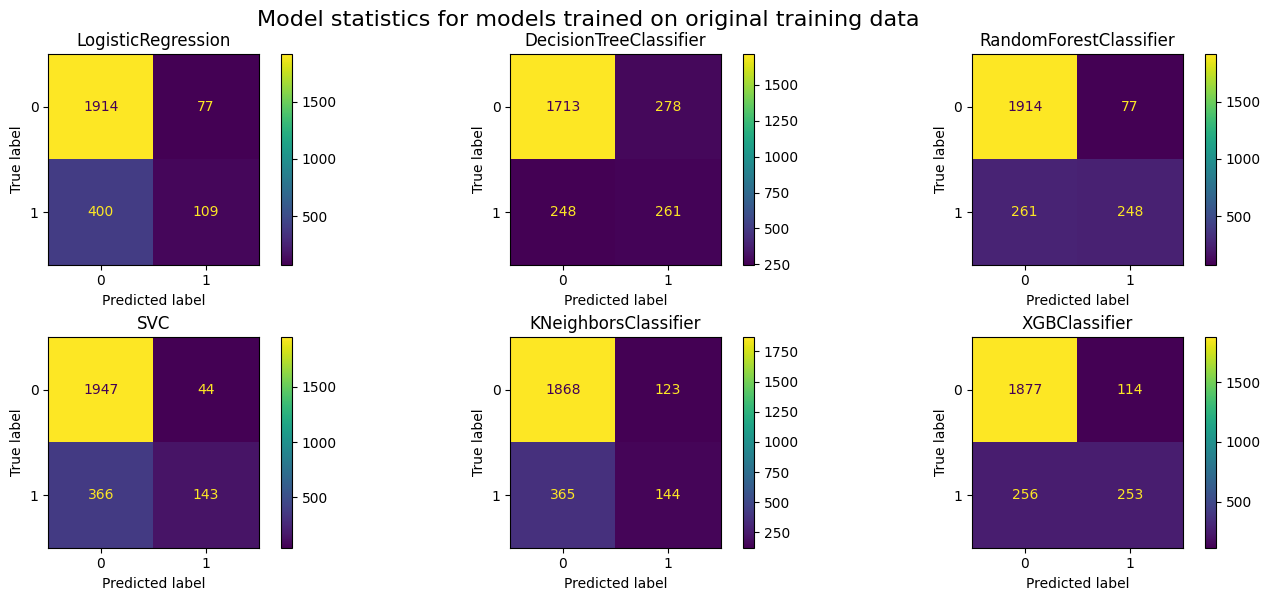

In [15]:
models = [
    LogisticRegression(),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    SVC(),
    KNeighborsClassifier(),
    XGBClassifier(),
]
model_report = pd.DataFrame(
    columns=[
        "Model",
        "Accuracy Score",
        "Precision",
        "Recall",
        "F1 Score",
        "Specificity",
        "Balanced Accuracy Score",
    ]
)
fig, axes = plt.subplots(2, 3, figsize=(14, 6))

for index, model in enumerate(models):
    model.fit(X_train.astype(float), y_train)
    predicted_values = model.predict(X_test.astype(float))
    plt.suptitle("Model statistics for models trained on original training data", fontsize=16)
    model_report.loc[index] = [
        str(model),
        accuracy_score(y_test, predicted_values),
        precision_score(y_test, predicted_values),
        recall_score(y_test, predicted_values),
        f1_score(y_test, predicted_values),
        recall_score(y_test, predicted_values, pos_label=0),
        balanced_accuracy_score(y_test, predicted_values),
    ]
    ConfusionMatrixDisplay(confusion_matrix(y_test, predicted_values)).plot(
        ax=axes[index // 3, index % 3]
    )
    axes[index // 3, index % 3].set_title(model.__class__.__name__)
fig.tight_layout(pad=0.5)
plt.show()


<p>These will serve as our base models for comparison with future models. Firstly, lets compare them with SMOTE trained models</p>

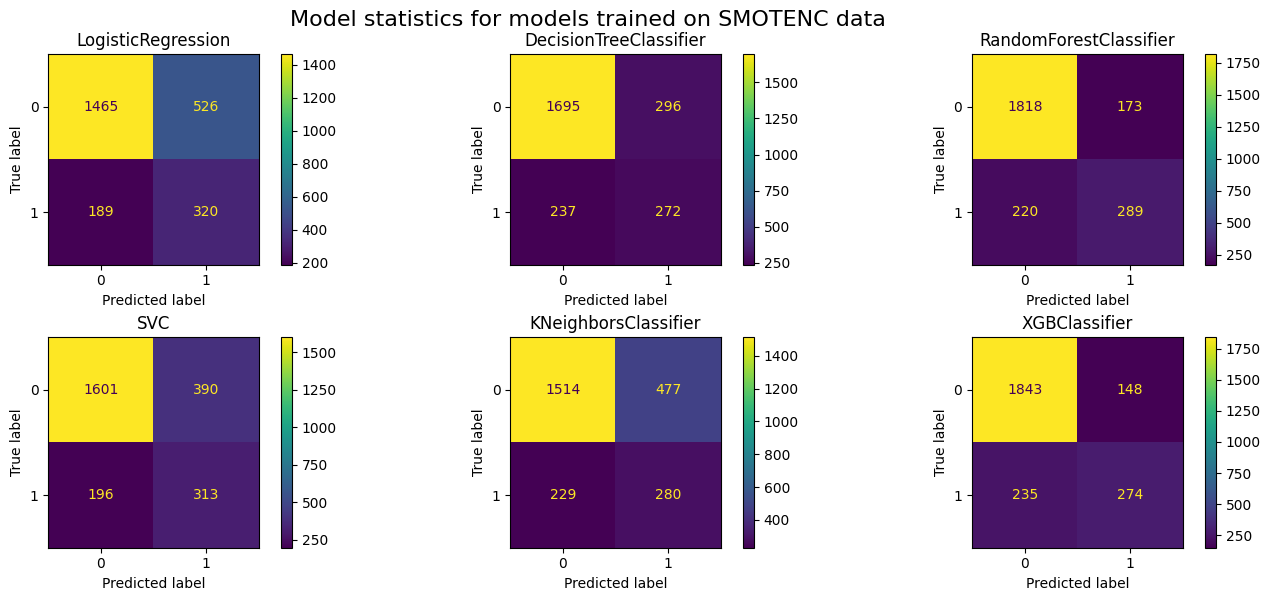

In [16]:
models = [
    LogisticRegression(),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    SVC(),
    KNeighborsClassifier(),
    XGBClassifier(),
]
model_report_sm = pd.DataFrame(
    columns=[
        "Model",
        "Accuracy Score",
        "Precision",
        "Recall",
        "F1 Score",
        "Specificity",
        "Balanced Accuracy Score",
    ]
)
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for index, model in enumerate(models):
    model.fit(X_train_sm.astype(float), y_train_sm)
    plt.suptitle("Model statistics for models trained on SMOTENC data", fontsize=16)
    predicted_values = model.predict(X_test.astype(float))
    model_report_sm.loc[index] = [
        str(model),
        accuracy_score(y_test, predicted_values),
        precision_score(y_test, predicted_values),
        recall_score(y_test, predicted_values),
        f1_score(y_test, predicted_values),
        recall_score(y_test, predicted_values, pos_label=0),
        balanced_accuracy_score(y_test, predicted_values),
    ]
    ConfusionMatrixDisplay(confusion_matrix(y_test, predicted_values)).plot(
        ax=axes[index // 3, index % 3]
    )
    axes[index // 3, index % 3].set_title(model.__class__.__name__)

fig.tight_layout(pad=0.5)
plt.show()

In [17]:
model_report

,Model,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,LogisticRegression(),0.8092,0.586022,0.214145,0.313669,0.961326,0.587736
1,DecisionTreeClassifier(),0.7896,0.484230,0.512770,0.498092,0.860372,0.686571
2,RandomForestClassifier(),0.8648,0.763077,0.487230,0.594724,0.961326,0.724278
3,SVC(),0.8360,0.764706,0.280943,0.410920,0.977901,0.629422
4,KNeighborsClassifier(),0.8048,0.539326,0.282908,0.371134,0.938222,0.610565
5,"XGBClassifier(base_score=None, booster=None, c...",0.8520,0.689373,0.497053,0.577626,0.942742,0.719898


In [18]:
model_report_sm

,Model,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,LogisticRegression(),0.7140,0.378251,0.628684,0.472325,0.735811,0.682247
1,DecisionTreeClassifier(),0.7868,0.478873,0.534381,0.505107,0.851331,0.692856
2,RandomForestClassifier(),0.8428,0.625541,0.567780,0.595263,0.913109,0.740444
3,SVC(),0.7656,0.445235,0.614931,0.516502,0.804119,0.709525
4,KNeighborsClassifier(),0.7176,0.369881,0.550098,0.442338,0.760422,0.655260
5,"XGBClassifier(base_score=None, booster=None, c...",0.8468,0.649289,0.538310,0.588614,0.925665,0.731988


<p>These two reports primarily serve to indicate how the models performed before any hyperoptimizing was performed, with the intent of getting a general idea of untuned model performance as well as evaluating model performance when trained on the original dataset compared to their performance on a synthetic dataset.</p>

<hr style="width: 100%; height: 1px; border-top: 1px solid red;">

<p>These scores show something interesting. Balancing the dataset via SMOTENC has made a marked improvement in recall and balanced accuracy score, though it has made a marked decrease on specificity across all models; however, this reduction can be attributed to the fact that prior to SMOTENC the negative class had a significantly higher representation in the dataset, which could have led to the model being biased towards it.  Through this  can select the models with the greatest potential for accurate prediction and select the models I can immediately use for hyperparameter tuning. Decision Tree Classifier shows extreme overfitting on the training set, as does the random forest classifier. This can be potentially fixed using hyperparameter tuning and regularization</p>